# Does HAR beat simple benchmarks?

HAR (Corsi, 2009) forecasts tomorrow's volatility from its average over the
last day, week and month. This notebook asks, for every asset, whether that
beats four simpler forecasts, out of sample, by a margin unlikely to be luck.
It also explains the methods every model notebook shares: walk-forward
forecasts, the smearing correction, QLIKE and the Diebold–Mariano test.

The data are built and checked in `01_data`. Every number that depends on the
data is printed by the code cell it comes from.

In [1]:
import _display
import numpy as np
import pandas as pd
from _display import COLORS, by_asset, model_table, pair
from design import ASSETS, DESIGN, HAR, LAYOUT, LOG_RV, LOG_RV_MEANS

from rvol.data.market import sessions_per_year
from rvol.data.preparation import build_forecast_data
from rvol.data.volatility import annualized_volatility_pct, daily_dataset
from rvol.evaluation import default_hac_lags, hac_lag_grid, hac_sensitivity, results_table
from rvol.models import ExponentialSmoothing, ForecastModel, LinearRegression
from rvol.walkforward import fit_known

_display.use_style()

In [2]:
# Helpers used only by this notebook.
# Short names for the design's choices.
CANDIDATE, LOSS_LABEL = DESIGN.candidate, DESIGN.loss_name


def coefficients(run, model, before):
    # The model's intercept and slopes fitted on every outcome observed before ``before``.
    fitted = fit_known(run.data, model, before=before)
    return pd.Series(
        [fitted.intercept, *fitted.coefficients], index=["intercept", *model.regressors]
    )


LOWER, WINS = f"{CANDIDATE} lower by", f"{CANDIDATE} wins"
BEST_SESSIONS, WORST = 10, 5


def benchmark_gains(run):
    # Benchmark loss minus HAR's loss, per session and benchmark.
    losses = run.losses()
    return losses[BENCHMARK_NAMES].sub(losses[CANDIDATE], axis=0)


def verdict(run):
    table = results_table(run.evaluation).drop(CANDIDATE)
    worst_p = hac_table(run).max().max()
    beats = "beats" if (table[LOWER] > 0).all() else "does not beat"
    level = "below" if worst_p < 0.01 else "not below"
    return (
        f"{pair(run.series)}: {CANDIDATE} {beats} every benchmark, its mean {LOSS_LABEL} "
        f"{table[LOWER].min():.0%} to {table[LOWER].max():.0%} lower; largest one-sided DM "
        f"p-value at any HAC lag tried {worst_p:.1e}, {level} 1%; against naive it has the "
        f"lower loss on {table.loc['naive', WINS]:.0%} of sessions"
    )


def har_coefficients(run):
    fitted = coefficients(run, HAR, DESIGN.evaluation_start)
    slopes = fitted.drop("intercept")
    shortest = slopes.index[0]  # columns follow increasing windows
    print(
        f"{pair(run.series)}: slope on the last session alone {slopes[shortest]:.2f}, on the "
        f"longer averages together {slopes.drop(shortest).sum():.2f}, sum {slopes.sum():.2f}"
    )
    return fitted


def smearing_factors(run):
    factors = run.evaluation.forecasts.groupby("model")["smearing_factor"]
    return factors.agg(["mean", "min", "max"]).loc[MODEL_NAMES]


def recent_paths(run, months=6):
    per_year = sessions_per_year(DAILY[run.series]["date"])
    variance = run.evaluation.forecasts
    since = variance["target_date"].max() - pd.DateOffset(months=months)
    recent = variance.loc[variance["target_date"] >= since]
    realized = recent.loc[recent["model"] == CANDIDATE]
    paths = {
        model: annualized_volatility_pct(
            recent.loc[recent["model"] == model, "predicted"], per_year
        )
        for model in [CANDIDATE, "naive"]
    }
    return realized["target_date"], annualized_volatility_pct(realized["actual"], per_year), paths


def concentration(run):
    gain = benchmark_gains(run)
    return pd.DataFrame(
        {
            "final advantage": gain.sum().round(2),
            f"share from the best {BEST_SESSIONS} sessions": gain.apply(
                lambda column: column.nlargest(BEST_SESSIONS).sum() / column.sum()
            ).round(2),
            "month with the largest gain": gain.groupby(gain.index.to_period("M")).sum().idxmax(),
        }
    )


def hac_table(run):
    lags = hac_lag_grid(len(run.losses()))
    table = hac_sensitivity(run.evaluation.losses, CANDIDATE, lags=lags)
    return table.pivot(index="baseline_model", columns="hac_lags", values="p_value").loc[
        BENCHMARK_NAMES
    ]


def monthly_losses(run):
    losses = run.evaluation.losses.assign(
        month=run.evaluation.losses["target_date"].dt.strftime("%Y-%m")
    )
    return losses.pivot_table(index="month", columns="model", values="loss", aggfunc="mean")[
        MODEL_NAMES
    ]


def worst_days(run):
    per_year = sessions_per_year(DAILY[run.series]["date"])
    candidate = run.evaluation.losses.query("model == @CANDIDATE")
    worst = candidate.nlargest(WORST, "loss")
    share = worst["loss"].sum() / candidate["loss"].sum()
    ratio = np.sqrt(worst["actual"] / worst["predicted"])
    print(
        f"{pair(run.series)}: {WORST} sessions ({WORST / len(candidate):.1%} of the sample) make "
        f"up {share:.0%} of {CANDIDATE}'s loss; realized volatility was {ratio.min():.1f} to "
        f"{ratio.max():.1f} times the forecast"
    )
    return pd.DataFrame(
        {
            "session": worst["target_date"].dt.date,
            "realized vol %": annualized_volatility_pct(worst["actual"], per_year).round(1),
            f"{CANDIDATE} forecast vol %": annualized_volatility_pct(
                worst["predicted"], per_year
            ).round(1),
            LOSS_LABEL: worst["loss"].round(2),
        }
    ).set_axis(pd.RangeIndex(1, WORST + 1, name="rank"))

## The models

Every model predicts $y_{t+1} = \log \mathrm{RV}_{t+1}$ from information
available at the end of session $t$. The models are special cases of two
forecasting rules.

**Exponential smoothing** with fixed weights forecasts $s_t$, where
$s_k = \lambda\,s_{k-1} + (1-\lambda)\,y_k$ and the decay $\lambda \in [0, 1)$
is chosen in advance, not estimated.

**Linear regression** forecasts $a + x_t^\top b$, with $a$ and $b$ estimated by
least squares on the past.

| rule | model | forecast of $y_{t+1}$ |
|---|---|---|
| smoothing | naive | $y_t$, the case $\lambda = 0$: tomorrow looks like today |
| smoothing | EWMA | $s_t$ with RiskMetrics' decay for squared returns, here applied to log RV |
| regression | historical mean | $a$: no regressors, so $a$ is the mean of past $y$ |
| regression | AR(1) | $a + b\,y_t$ |
| regression | HAR | $a + b_d\,y_t + b_w\,\bar y^{(w)}_t + b_m\,\bar y^{(m)}_t$ |

$\bar y^{(w)}_t$ and $\bar y^{(m)}_t$ are the means of $y$ over roughly the last
week and month of sessions, a simple way to capture the slow decay of
autocorrelation seen in `01_data`. In the code, `log_rv_mean_k` is the mean of
log RV over the latest $k$ sessions, so `log_rv_mean_1` is today's value. HAR
is defined once, in `design.py`, because every model notebook tests against
the same HAR; the benchmarks are defined here.

**Walk-forward.** Each session, every model is refitted on all outcomes
observed so far and forecasts the next session only. No forecast ever uses data
from its own future. Forecasts made before the evaluation start form the
*calibration window*: they calibrate the correction in section 2, and they are
never scored.

In [3]:
BENCHMARKS = [
    ForecastModel("historical_mean", LinearRegression()),  # no regressors: the mean
    ForecastModel("naive", ExponentialSmoothing(decay=0.0)),  # tomorrow equals today
    ForecastModel("EWMA", ExponentialSmoothing(decay=0.94)),  # RiskMetrics' decay
    ForecastModel("AR1", LinearRegression(), (LOG_RV_MEANS.column(1),)),
]
MODELS = [HAR, *BENCHMARKS]
MODEL_NAMES = [model.name for model in MODELS]
BENCHMARK_NAMES = MODEL_NAMES[1:]
display(_display.design_table(DESIGN, ASSETS))
model_table(MODELS)

,study design
assets,EUR/USD
minimum training sessions,252
first forecast target,2024-10-01
evaluation start,2025-01-01
last forecast target,2026-09-30
candidate model,HAR
loss,QLIKE


,rule,settings,regressors
model,,,
HAR,LinearRegression,ridge = 0.0,"log_rv_mean_1, log_rv_mean_5, log_rv_mean_22"
historical_mean,LinearRegression,ridge = 0.0,none
naive,ExponentialSmoothing,decay = 0.0,none
EWMA,ExponentialSmoothing,decay = 0.94,none
AR1,LinearRegression,ridge = 0.0,log_rv_mean_1


In [4]:
DAILY = {asset: daily_dataset(asset, LAYOUT) for asset in ASSETS}
DATA = {
    asset: build_forecast_data(DAILY[asset], [LOG_RV_MEANS], value_col=LOG_RV) for asset in ASSETS
}
RUNS = {asset: DESIGN.run(DATA[asset], MODELS, series=asset) for asset in ASSETS}

## Answer

In [5]:
for run in RUNS.values():
    print(verdict(run))

EUR/USD: HAR beats every benchmark, its mean QLIKE 16% to 53% lower; largest one-sided DM p-value at any HAC lag tried 2.4e-03, below 1%; against naive it has the lower loss on 51% of sessions


Where HAR beats every benchmark at every lag, the answer is yes. The evidence
below says how: HAR avoids the large misses rather than winning every day, and
it draws on persistence at several horizons, with the weekly and monthly
averages carrying most of its weight.

## 1. What HAR learns

The coefficients fitted on everything before the evaluation period, one column
per asset.

In [6]:
pd.DataFrame({pair(asset): har_coefficients(run) for asset, run in RUNS.items()}).round(3)

EUR/USD: slope on the last session alone 0.13, on the longer averages together 0.72, sum 0.85


,EUR/USD
intercept,-1.692
log_rv_mean_1,0.125
log_rv_mean_5,0.468
log_rv_mean_22,0.255


When the longer averages carry most of the weight, tomorrow's volatility
depends more on the recent level than on today's single, noisy measurement.
When the slopes sum to less than one, forecasts are pulled back towards a
long-run level.

## 2. From log forecasts back to variance

The models forecast $\log \mathrm{RV}$, but the quantity we care about is RV
itself. Simply exponentiating is biased: if $y_{t+1} = \hat y_{t+1} + \varepsilon$
with mean-zero errors, then

$$
\mathbb{E}[\mathrm{RV}_{t+1}] = e^{\hat y_{t+1}}\,\mathbb{E}[e^{\varepsilon}] > e^{\hat y_{t+1}}
$$

by Jensen's inequality, so $e^{\hat y}$ is too low on average. The **Duan
smearing** correction multiplies each forecast by the average of $e^{\varepsilon}$
over the model's past errors, using only errors already observed when the
forecast is made. For normal errors the factor would be $e^{\sigma^2/2}$, so it
grows with the spread of the errors.

In [7]:
FACTORS = {asset: smearing_factors(run) for asset, run in RUNS.items()}
for asset, factors in FACTORS.items():
    mean = factors.loc[CANDIDATE, "mean"]
    print(
        f"{pair(asset)}: {CANDIDATE}'s mean factor {mean:.2f}, so without smearing its "
        f"variance forecasts would be {1 - 1 / mean:.0%} too low on average; "
        f"largest mean factor: {factors['mean'].idxmax()}"
    )
by_asset(FACTORS).round(3)

EUR/USD: HAR's mean factor 1.26, so without smearing its variance forecasts would be 20% too low on average; largest mean factor: historical_mean


,mean,min,max
model,,,
HAR,1.256,1.169,1.401
historical_mean,1.730,1.342,2.225
naive,1.302,1.230,1.511
EWMA,1.287,1.186,1.507
AR1,1.404,1.205,1.623


Forecasts against what happened, for the last six months of the sample, on the
annualized-volatility scale, with the naive forecast for comparison. The naive
forecast copies yesterday, so it chases every spike one day late; HAR blends
today with the weekly and monthly levels, so a single spike only partly
carries over.

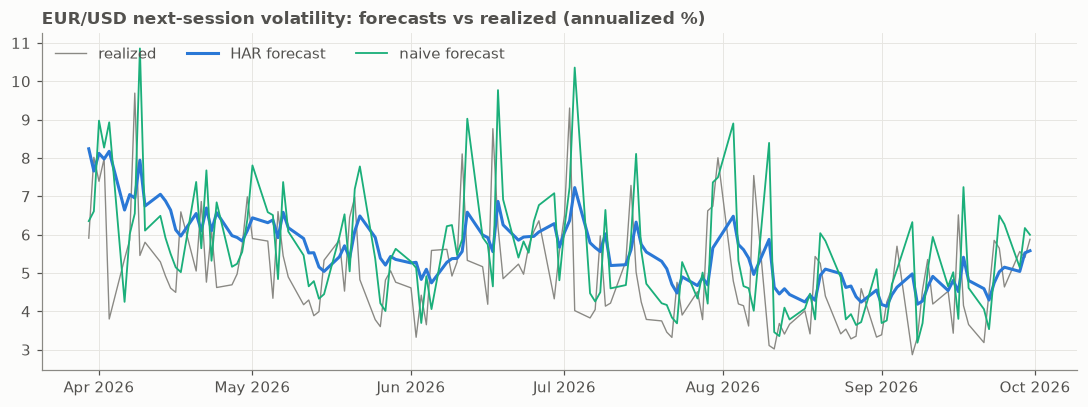

In [8]:
_display.forecasts_vs_realized(
    {pair(asset): recent_paths(run) for asset, run in RUNS.items()}, COLORS, highlight=CANDIDATE
);

## 3. Results

**QLIKE.** Each forecast $h$ of the variance is scored against the realized
$\mathrm{RV}$ with

$$
L(\mathrm{RV}, h) = \frac{\mathrm{RV}}{h} - \log\frac{\mathrm{RV}}{h} - 1 \;\ge 0 .
$$

It is zero for a perfect forecast and depends only on the ratio, so a 20% miss
costs the same on a calm day as on a turbulent one. It punishes under-forecasting
more than over-forecasting: missing a 2× move costs 0.31, over-predicting by 2×
costs 0.19. And it ranks models correctly even though RV is only a noisy
measure of the true variance (Patton, 2011).

**Diebold–Mariano test.** For each benchmark, the test asks whether HAR's lower
average loss could be luck. With $d_t$ the benchmark's loss minus HAR's on
session $t$, it tests $\mathbb{E}[d_t] = 0$ against $\mathbb{E}[d_t] > 0$ with
$\bar d$ divided by its standard error. The p-value is one-sided: a small value
means HAR's expected loss is lower. **HAR wins** is the share of sessions on
which HAR had the strictly lower loss.

In [9]:
by_asset({asset: results_table(run.evaluation) for asset, run in RUNS.items()}).style.format(
    {LOSS_LABEL: "{:.3f}", LOWER: "{:.1%}", "DM p-value": "{:.1e}", WINS: "{:.0%}"}, na_rep="—"
)

,QLIKE,HAR lower by,DM p-value,HAR wins
model,,,,
HAR,0.152,0.0%,—,—
AR1,0.182,16.3%,2.4e-05,61%
EWMA,0.184,17.2%,8.1e-04,63%
naive,0.192,20.6%,2.2e-04,51%
historical_mean,0.326,53.2%,1.9e-11,76%


Compare the win rate with the reduction in mean loss. A win rate near one half
together with a clearly lower mean loss means HAR wins by avoiding the large
misses, not by winning every day: the naive forecast copies every spike into
the next day and pays for it on the following session.

Is the advantage steady or does it come from a few days? The cumulative sum of
the loss difference, benchmark minus HAR, rises when HAR does better. A steady
climb is a steady advantage; steps are a few turbulent sessions. The table
gives the final advantage, the share of it earned on the ten best sessions, and
the month that contributed most.

,final advantage,share from the best 10 sessions,month with the largest gain
model,,,
historical_mean,78.50,0.19,2025-04
naive,17.96,0.54,2025-01
EWMA,14.38,0.51,2026-01
AR1,13.44,0.43,2025-12


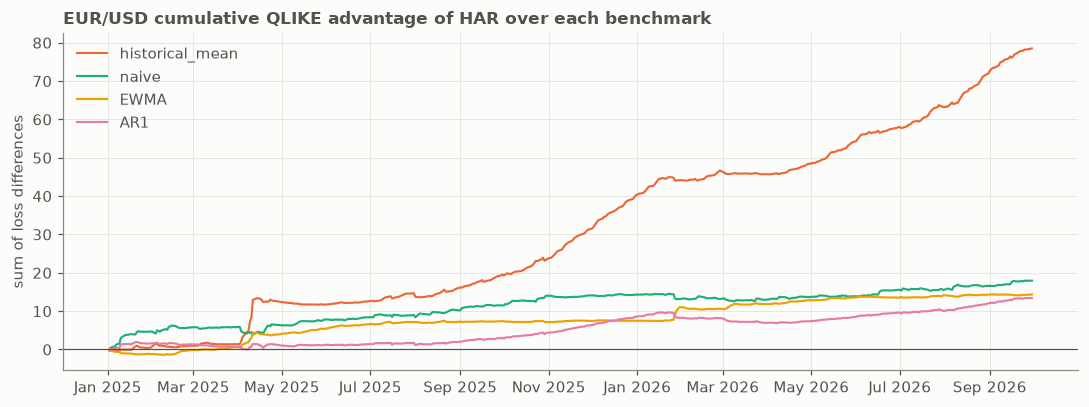

In [10]:
_display.cumulative_advantage(
    {pair(asset): benchmark_gains(run).cumsum() for asset, run in RUNS.items()},
    COLORS,
    title=f"cumulative {LOSS_LABEL} advantage of {CANDIDATE} over each benchmark",
)
by_asset({asset: concentration(run) for asset, run in RUNS.items()})

## 4. Robustness

### Does the verdict depend on the HAC lag?

The DM test has to account for the fact that neighbouring sessions are not
independent evidence: if HAR handles a turbulent week better, it wins that
week's sessions together. The test corrects for this with a Newey–West (HAC)
variance that also counts how each session's loss difference moves with those of
a chosen number of previous sessions, the lags. There is no single right number.
The usual rule, $\lfloor 4\,(n/100)^{2/9} \rfloor$ for $n$ sessions, gives the
count printed below; we repeat the test from no lags up to six times that
count. More lags make the correction stronger, so p-values tend to rise.

In [11]:
for asset, run in RUNS.items():
    n_obs = len(run.losses())
    usual = default_hac_lags(n_obs)
    print(f"{pair(asset)}: {n_obs} evaluation sessions, the usual rule gives {usual} lags")
by_asset({asset: hac_table(run) for asset, run in RUNS.items()}).style.format("{:.1e}")

EUR/USD: 453 evaluation sessions, the usual rule gives 5 lags


hac_lags,0,1,2,3,4,5,10,20,30
baseline_model,,,,,,,,,
historical_mean,3.6e-26,2.8e-19,1.4e-15,1.0e-13,2.3e-12,1.9e-11,2.8e-09,7.6e-08,3.1e-07
naive,2.0e-04,2.0e-04,1.8e-04,1.9e-04,2.1e-04,2.2e-04,3.5e-04,3.3e-04,5.7e-04
EWMA,1.4e-06,4.0e-05,2.0e-04,4.1e-04,6.3e-04,8.1e-04,1.0e-03,1.0e-03,1.2e-03
AR1,1.2e-05,1.1e-05,1.5e-05,1.8e-05,2.1e-05,2.4e-05,1.6e-04,9.0e-04,2.4e-03


### Is the advantage spread over the sample?

Mean QLIKE per model and calendar month; the best model of each month is
highlighted. If HAR leads in most months and no other model leads often, the
result does not rest on a few unusual months.

In [12]:
MONTHLY = {asset: monthly_losses(run) for asset, run in RUNS.items()}
for asset, monthly in MONTHLY.items():
    leaders = monthly.idxmin(axis=1).value_counts().reindex(MODEL_NAMES, fill_value=0)
    print(f"{pair(asset)}, months led by each model, of {len(monthly)}: {leaders.to_dict()}")
by_asset(MONTHLY).style.highlight_min(axis=1, props=_display.HIGHLIGHT).format("{:.3f}")

EUR/USD, months led by each model, of 21: {'HAR': 11, 'historical_mean': 1, 'naive': 2, 'EWMA': 4, 'AR1': 3}


model,HAR,historical_mean,naive,EWMA,AR1
month,,,,,
2025-01,0.259,0.285,0.474,0.205,0.330
2025-02,0.214,0.234,0.267,0.267,0.203
2025-03,0.087,0.106,0.088,0.121,0.056
2025-04,0.313,0.813,0.334,0.469,0.329
2025-05,0.117,0.086,0.185,0.180,0.123
2025-06,0.096,0.136,0.124,0.151,0.104
2025-07,0.137,0.228,0.163,0.163,0.152
2025-08,0.284,0.339,0.345,0.286,0.295
2025-09,0.114,0.283,0.170,0.124,0.162


### The worst days

HAR's largest QLIKE losses. QLIKE punishes under-forecasts hardest, so these
are sessions on which realized volatility jumped far above the forecast:
sudden moves, usually driven by news, that no model built only on past
volatility can anticipate.

In [13]:
by_asset({asset: worst_days(run) for asset, run in RUNS.items()})

EUR/USD: 5 sessions (1.1% of the sample) make up 12% of HAR's loss; realized volatility was 1.9 to 2.3 times the forecast


,session,realized vol %,HAR forecast vol %,QLIKE
rank,,,,
1,2025-08-01,19.0,8.3,2.63
2,2026-03-23,16.8,8.2,1.74
3,2025-04-03,18.6,9.6,1.43
4,2026-01-27,13.3,6.9,1.41
5,2025-01-20,17.6,9.2,1.33


**Caveats.** AR(1) and the historical mean are nested in HAR, so their DM tests
are conservative (Clark & West, 2007). The models are fitted by least squares on
log RV but scored by QLIKE on variance, so none of them is tuned for the loss
that ranks them.